## 1.1 Importing data

In [2]:
import pandas as pd

df = pd.read_csv("../data/cities.csv")
print(df.head())
print(df.shape)

     City          X          Y
0  City_1  37.454012  95.071431
1  City_2  73.199394  59.865848
2  City_3  15.601864  15.599452
3  City_4   5.808361  86.617615
4  City_5  60.111501  70.807258
(50, 3)


## 1.2 Preparing coordinates

In [4]:
coords = list(zip(df["X"], df["Y"]))
print(len(coords))
print(coords[:3])

50
[(37.45401188, 95.07143064), (73.19939418, 59.86584842), (15.60186404, 15.59945203)]


## 1.3 Distance between cities

In [ ]:
import math

In [7]:
def distance(a, b):
    x1, y1 = coords[a]
    x2, y2 = coords[b]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

50.17136010935256


## Route length

In [8]:
def route_length(route):
    total = 0
    for i in range(len(route)):
        total += distance(route[i], route[(i + 1) % len(route)])
    return total

227.25986949958047


## Random route

In [ ]:
import random

In [9]:
def random_route(n):
    route = list(range(n))
    random.shuffle(route)
    return route


random.seed(1)
r = random_route(50)
print(r[:10])
print(route_length(r))

[2, 15, 47, 9, 21, 29, 48, 5, 46, 14]
2723.3508829346997


## Plotting a route

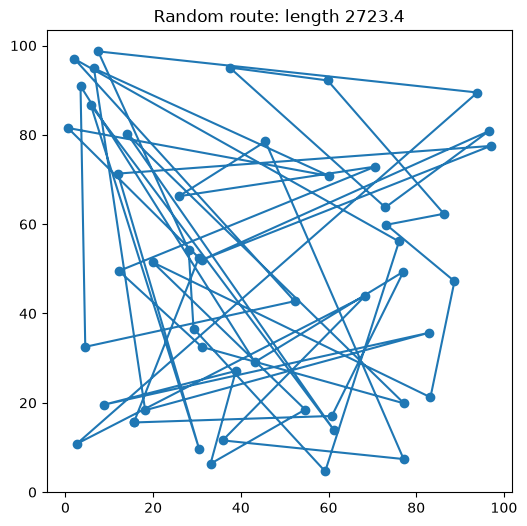

In [10]:
import matplotlib.pyplot as plt


def plot_route(route, title="Route"):
    order = route + [route[0]]
    xs = [coords[c][0] for c in order]
    ys = [coords[c][1] for c in order]
    plt.figure(figsize=(6, 6))
    plt.plot(xs, ys, "o-")
    plt.title(f"{title}: length {route_length(route):.1f}")
    plt.show()


plot_route(r, "Random route")

## Neighbour move

In [11]:
def swap_neighbour(route):
    new_route = route.copy()
    i, j = random.sample(range(len(route)), 2)
    new_route[i], new_route[j] = new_route[j], new_route[i]
    return new_route


r2 = swap_neighbour(r)
print(route_length(r), route_length(r2))

2723.3508829346997 2765.217597013673
